Convert nielson_conversion.json to nielson_data.csv

In [7]:
# Make the Nielson JSON easy to read as a spreadsheet
from nielson_data import NielsonDataCSVConverter

# Define file paths
json_file = "nielson_ome.json"
csv_file = "nielson_data.csv"

# Create an instance of the converter
converter = NielsonDataCSVConverter(json_file, csv_file)

# Convert the JSON to CSV
converter.convert_to_csv()

JSON data has been successfully converted to nielson_data.csv


Add priority assignments to each opioid in nielson_conversions.json

In [6]:
# Import the class
from nielson_data import NielsonDataPriorityUpdater

# Define the JSON file path
json_file = "nielson_ome.json"

# Create an instance of the updater
updater = NielsonDataPriorityUpdater(json_file)

# Define the priority dictionary
priority_dict = {
    1: ['oral_hydromorphone', 'oral_morphine', 'oral_oxycodone','iv_hydromorphone','iv_morphine'],
    2: ['oral_codeine', 'oral_hydrocodone', 'oral_methadone', 'oral_oxymorphone',
        'oral_tapentadol','oral_tramadol','sublingual_buprenorphine','transdermal_fentanyl',
        'iv_fentanyl','sc_fentanyl']
}

# Update the priorities in the JSON file
updater.update_priorities(priority_dict)

Updated JSON data has been saved to nielson_ome.json


Calculate the equivalent opioids from nielson_ome.json

In [2]:
# Conversion Service
from opioid import Opioid
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS

conversion_service = ConversionService(NIELSON_CONVERSIONS)

iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone")
oral_morphine = Opioid(administration_method="oral", substance="morphine")

random_dose = conversion_service.generate_random_dose(iv_fentanyl)
print(f"Random dose for {iv_fentanyl.administration_method}_{iv_fentanyl.substance}: {random_dose:.2f} {iv_fentanyl.unit}")

equivalent_dose_oral_morphine = conversion_service.calculate_expected_dose(random_dose, iv_fentanyl, oral_morphine)
print(f"Equivalent dose for {oral_morphine.administration_method}_{oral_morphine.substance}: {equivalent_dose_oral_morphine:.2f} {oral_morphine.unit}")

Random dose for iv_fentanyl: 56.23 mcg/day
Equivalent dose for oral_morphine: 11.25 mg/day


Construct a prompt

In [4]:
# Prompt Service
from prompt_service import PromptService, PromptedOpioidConversion
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the PromptService
prompt_service = PromptService(ConversionService(NIELSON_CONVERSIONS))

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object without specifying `from_dose` or `conversion_service`
prompted_conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    model="google/gemini-2.5-pro")

# Generate the prompt using the PromptService instance
generated_prompt = prompted_conversion.generate_prompt(prompt_service)

# Print the generated prompt
print("Generated Prompt:")
print(generated_prompt)

# Print the randomly generated `from_dose` and calculated `expected_to_dose`
print(f"\nRandomly Generated Dose: {prompted_conversion.from_dose:.2f} {iv_fentanyl.unit}")
print(f"Expected Dose: {prompted_conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")

Generated Prompt:
Convert 85.09 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 85.09 mcg/day of fentanyl (iv)?


Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.

Randomly Generated Dose: 85.09 mcg/day
Expected Dose: 17.02 mg/day


Ask the model for the equivalent opioid dose

In [5]:
# Run a single conversion with an instance of PromptedOpioidConversion
from conversion_service import ConversionService
from prompt_service import PromptService, PromptedOpioidConversion
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the OpenAI client once
PromptedOpioidConversion.initialize_client()

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object
conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    model="google/gemini-2.5-pro",
    include_nielson=True,
    include_examples=True
)

# Generate the prompt
conversion.generate_prompt(prompt_service=PromptService(ConversionService(NIELSON_CONVERSIONS)))

# Query the model
observed_dose = conversion.ask_model()

# Print the results
print("Generated Prompt:")
print(conversion.prompt)
print(f"Observed Dose: {observed_dose:.2f} {oral_hydromorphone.unit}")
print(f"Expected Dose: {conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")
print(f"Ratio Observed/Expected: {conversion.ratio_observed_expected:.2f}")

Generated Prompt:
Convert 70.64 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 70.64 mcg/day of fentanyl (iv)?

Use the following conversion factor(s):
0.2 OME: 1 mcg/day of fentanyl (iv) is equivalent to 0.2 mg/day morphine (oral).
0.2 OME for fentanyl (iv) means 10 mg/day of morphine (oral) is equivalent to 50.00 mcg/day of fentanyl (iv).
And 120 mg/day of morphine (oral) is equivalent to 600.00 mcg/day of fentanyl (iv).

Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.
Observed Dose: 14.13 mg/day
Expected Dose: 14.13 mg/day
Ratio Observed/Expected: 1.00


Run an experiment converting opioids across prompting conditions and models

In [ ]:
# Run an experiment converting opioids across prompting conditions and models
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize all clients
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list_ome = OpioidPairGenerator(lambda priority: priority <= 2 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=False, use_permutations=False)

opioid_pairs = OpioidPairGenerator(lambda priority: priority == 1 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=True, use_permutations=True)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False}
]

# OpenRouter models
models = [
    "openai/gpt-4.1",
    "anthropic/claude-3.5-sonnet:20241022",
    "mistralai/mistral-large-2407",
    "mistralai/mixtral-8x22b-instruct",
    "google/gemini-2.5-pro",
    "cohere/command-r-plus-08-2024",
    "ai21/jamba-large-1.7",
    "ai21/jamba-mini-1.7",
    "qwen/qwen-2.5-72b-instruct",
    "meta-llama/llama-3.3-70b-instruct",
    "deepseek/deepseek-chat"
]

# Run OME experiment
experiment_ome = Experiment(opioid_list_ome, prompt_conditions, models, repetitions=18)
experiment_ome.run()
experiment_ome.save_to_csv("experiment_results.csv")

# Print the OME experiment ID
print(f"Experiment ID: {experiment_ome.experiment_id}")

# Run pairs experiment
experiment_pairs = Experiment(opioid_pairs, prompt_conditions, models, repetitions=18)
experiment_pairs.run()
experiment_pairs.save_to_csv("experiment_results.csv")

# Print the pairs experiment ID
print(f"Experiment ID: {experiment_pairs.experiment_id}")

Organize all results by whether they include oral morphine

In [4]:
# Summarize all experiments in the CSV
from experiment_batch import ExperimentBatch

ExperimentBatch.reorganize_csv(
    input_file="experiment_results.csv",
    output_file="experiment_results_by_ome.csv"
)

# Load the full DataFrame
df = ExperimentBatch.summarize_csv("experiment_results_by_ome.csv")

Reorganized CSV saved to experiment_results_by_ome.csv
FULL CSV SUMMARY: experiment_results_by_ome.csv

Total entries: 21722
Unique experiments: 2
Unique models: 16
Experiment IDs: [np.int64(1), np.int64(2)]
Models: ['ai21/jamba-large-1.7', 'ai21/jamba-mini-1.7', 'anthropic/claude-3.5-sonnet:20241022', 'claude-3-5-haiku-20241022', 'cohere/command-r-plus-08-2024', 'deepseek/deepseek-chat', 'google/gemini-2.5-pro', 'gpt-3.5-turbo', 'gpt-4.1-mini', 'llama-3.3-70b-versatile', 'meta-llama/llama-3.3-70b-instruct', 'mistralai/mistral-large-2407', 'mistralai/mixtral-8x22b-instruct', 'models/gemini-2.5-flash', 'openai/gpt-4.1', 'qwen/qwen-2.5-72b-instruct']

COMPREHENSIVE SUMMARY TABLE
 experiment_id                                model  count       priority  pairs use_permutations include_nielson include_examples  from_opioids_count  to_opioids_count
             1                 ai21/jamba-large-1.7    534 Priority 1 & 2  False             None     False, True      False, True               

Organize results by opioid pairs, find consensus across prompt conditions

In [1]:
from opioid_pair_model_result import OpioidPairModelResult
from opioid_pair_consensus import OpioidPairConsensus
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS

# Initialize conversion service
conversion_service = ConversionService(NIELSON_CONVERSIONS)

# Process all combinations in the experiment_results_by_ome.csv
results = OpioidPairModelResult.process_all_combinations(
    csv_file="experiment_results_by_ome.csv",
    output_file="pair_model_analysis.csv",
    conversion_service=conversion_service,
    verbose=True
)

# Process all combinations in the pair_model_analysis.csv
results = OpioidPairConsensus.process_all_combinations(
    csv_file="pair_model_analysis.csv",
    output_file="opioid_pair_consensus.csv",
    conversion_service=conversion_service,
    verbose=True
)

# Update pair_model_analysis.csv with consensus results
updated_df = OpioidPairConsensus.update_pair_model_analysis(
    pair_model_csv="pair_model_analysis.csv",
    consensus_csv="opioid_pair_consensus.csv",
    output_csv="pair_model_analysis.csv",
    verbose=True
)

Processed 10/1354 combinations...
Processed 20/1354 combinations...
Processed 30/1354 combinations...
Processed 40/1354 combinations...


/Users/tanyamarton/opioid-conversion-experiment/opioid_pair_model_result.py:122: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r_value, p_value, std_err = stats.linregress(dose_to, log_coefficients)


Processed 50/1354 combinations...
Processed 60/1354 combinations...
Processed 70/1354 combinations...
Processed 80/1354 combinations...
Processed 90/1354 combinations...
Processed 100/1354 combinations...
Processed 110/1354 combinations...
Processed 120/1354 combinations...
Processed 130/1354 combinations...
Processed 140/1354 combinations...
Processed 150/1354 combinations...
Processed 160/1354 combinations...
Processed 170/1354 combinations...
Processed 180/1354 combinations...
Processed 190/1354 combinations...
Processed 200/1354 combinations...
Processed 210/1354 combinations...
Processed 220/1354 combinations...
Processed 230/1354 combinations...
Processed 240/1354 combinations...
Processed 250/1354 combinations...
Processed 260/1354 combinations...
Processed 270/1354 combinations...
Processed 280/1354 combinations...
Processed 290/1354 combinations...
Processed 300/1354 combinations...
Processed 310/1354 combinations...
Processed 320/1354 combinations...
Processed 330/1354 combin

In [3]:
from opioid_pair_visualizer import OpioidPairVisualizer
from bokeh.plotting import show

# Test with one pair
visualizer = OpioidPairVisualizer(
    experiment_results_csv="experiment_results_by_ome.csv",
    pair_model_csv="pair_model_analysis.csv",
    consensus_csv="opioid_pair_consensus.csv",
    from_opioid="iv_fentanyl",
    to_opioid="oral_morphine",
    prompt_conditions={'include_nielson': True, 'include_examples': False}
)

layout = visualizer.create_plot(output_html="test_visualization.html")
show(layout)

In [2]:
from opioid_pair_batch import OpioidPairBatch
from opioid_pair_batch_visualizer import OpioidPairBatchVisualizer

# Filter: include_nielson=True, include_examples=False, ome=True
filter_specs = [
    {
        "include_nielson": False,
        "include_examples": False,
        "ome": True,
        "exclude_self_pairs": True,
    }
]

batch = OpioidPairBatch.from_filter_specs(
    experiment_results_csv="experiment_results_by_ome.csv",
    pair_model_csv="pair_model_analysis.csv",
    consensus_csv="opioid_pair_consensus.csv",
    filter_specs=filter_specs,
)

vis = OpioidPairBatchVisualizer(
    batch,
    row_width=600,   # tweak if you want wider/narrower rows
    row_height=300,  # height per pair
)

# This will write an HTML file and (by default) open it in your browser
vis.create_grid(output_html="ome_n0_e0_batch.html")

Column(id='p12010', ...)

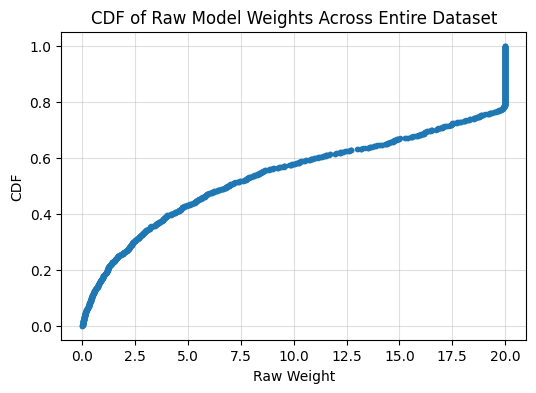

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your dataset
df = pd.read_csv("pair_model_analysis.csv")

# Extract raw weights
weights = df["weight"].dropna().astype(float)

# Sort for CDF
sorted_w = np.sort(weights)
cdf = np.arange(1, len(sorted_w) + 1) / len(sorted_w)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(sorted_w, cdf, marker='.', linestyle='none')

plt.xlabel("Raw Weight")
plt.ylabel("CDF")
plt.title("CDF of Raw Model Weights Across Entire Dataset")
plt.grid(True, alpha=0.4)

plt.show()


In [1]:
from experiment_batch import ExperimentBatch
import matplotlib.pyplot as plt

# Common parameters
models = ['ai21/jamba-large-1.7', 'ai21/jamba-mini-1.7',
   'anthropic/claude-3.5-sonnet:20241022',
   'claude-3-5-haiku-20241022', 'cohere/command-r-plus-08-2024',
   'deepseek/deepseek-chat', 'google/gemini-2.5-pro', 'gpt-3.5-turbo',
   'gpt-4.1-mini', 'llama-3.3-70b-versatile',
   'meta-llama/llama-3.3-70b-instruct',
   'mistralai/mistral-large-2407', 'mistralai/mixtral-8x22b-instruct',
   'models/gemini-2.5-flash', 'openai/gpt-4.1',
   'qwen/qwen-2.5-72b-instruct']

prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False},
]

experiment_names = {
    1: "OME (oral morphine included)",
    2: "Non-OME (oral morphine excluded)"
}

# Configuration for each plot
plot_configs = [
    {'name': 'nielson_effect_overall', 'experiment_ids': [1, 2]},
    {'name': 'nielson_effect_ome', 'experiment_ids': [1]},
    {'name': 'nielson_effect_non-ome', 'experiment_ids': [2]}
]

# First pass: calculate global min/max for consistent axis limits
all_with_nielson = []
all_without_nielson = []

for config in plot_configs:
    batch = ExperimentBatch(
        csv_file="experiment_results_by_ome.csv",
        models=models,
        prompt_conditions_list=prompt_conditions,
        experiment_ids=config['experiment_ids'],
        experiment_names=experiment_names
    )
    
    batch.df['model_clean'] = batch.df['model'].apply(
        lambda x: x.split('/')[-1] if '/' in x else x
    )
    
    for model in batch.df['model_clean'].unique():
        model_data = batch.df[batch.df['model_clean'] == model]
        
        with_nielson = model_data[model_data['include_nielson'] == True]
        if len(with_nielson) > 0:
            ratio_with = with_nielson['ratio_observed_expected']
            prop_tight = ((ratio_with >= 0.95) & (ratio_with <= 1.05)).sum() / len(ratio_with)
            all_with_nielson.append(prop_tight)
        
        without_nielson = model_data[model_data['include_nielson'] == False]
        if len(without_nielson) > 0:
            ratio_without = without_nielson['ratio_observed_expected']
            prop_broad = ((ratio_without >= 0.6) & (ratio_without <= 1.7)).sum() / len(ratio_without)
            all_without_nielson.append(prop_broad)

# Calculate global limits with margins
x_min, x_max = min(all_with_nielson), max(all_with_nielson)
y_min, y_max = min(all_without_nielson), max(all_without_nielson)
x_margin = (x_max - x_min) * 0.15
y_margin = (y_max - y_min) * 0.15
xlim = (x_min - x_margin, x_max + x_margin)
ylim = (y_min - y_margin, y_max + y_margin)

# Second pass: generate plots with consistent limits
for config in plot_configs:
    batch = ExperimentBatch(
        csv_file="experiment_results_by_ome.csv",
        models=models,
        prompt_conditions_list=prompt_conditions,
        experiment_ids=config['experiment_ids'],
        experiment_names=experiment_names
    )
    
    fig, ax = batch.plot_nielson_effect(figsize=(6, 5), range_broad=(0.6, 1.7))
    
    # Override with consistent axis limits
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
    plt.savefig(f"{config['name']}.pdf", bbox_inches='tight')
    print(f"Saved: {config['name']}.pdf")
    plt.show()

ImportError: cannot import name 'ExperimentFromCSVConverter' from 'experiment' (/Users/tanyamarton/opioid-conversion-experiment/experiment.py)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


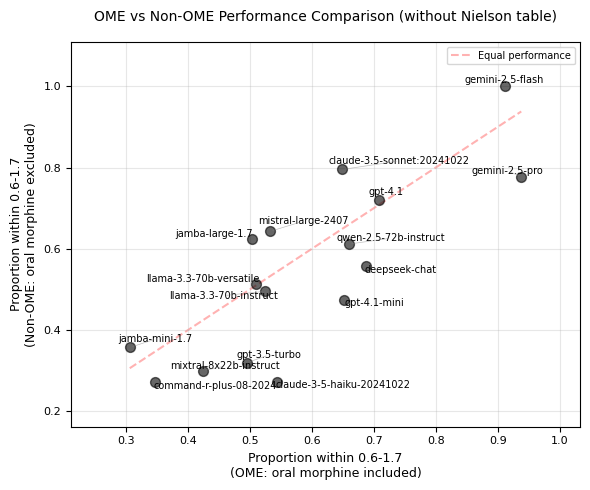

In [2]:
from experiment_batch import ExperimentBatch
import matplotlib.pyplot as plt

# Create an ExperimentBatch instance
batch = ExperimentBatch(
    csv_file="experiment_results_by_ome.csv",  # Use the reorganized CSV
    models = ['ai21/jamba-large-1.7', 'ai21/jamba-mini-1.7',
       'anthropic/claude-3.5-sonnet:20241022',
       'claude-3-5-haiku-20241022', 'cohere/command-r-plus-08-2024',
       'deepseek/deepseek-chat', 'google/gemini-2.5-pro', 'gpt-3.5-turbo',
       'gpt-4.1-mini', 'llama-3.3-70b-versatile',
       'meta-llama/llama-3.3-70b-instruct',
       'mistralai/mistral-large-2407', 'mistralai/mixtral-8x22b-instruct',
       'models/gemini-2.5-flash', 'openai/gpt-4.1',
       'qwen/qwen-2.5-72b-instruct'],
    prompt_conditions_list=[
        {"include_nielson": False, "include_examples": False},
    ],
    experiment_ids=[1, 2],  # 1 for OME=True, 2 for OME=False
    experiment_names={
        1: "OME (oral morphine included)",
        2: "Non-OME (oral morphine excluded)"
    }
)

fig, ax = batch.plot_ome_effect(figsize=(6, 5), range_broad=(0.6, 1.7), include_nielson=False)
plt.savefig('ome_effect.pdf', bbox_inches='tight')
plt.show()

Processed 10/1354 combinations...
Processed 20/1354 combinations...
Processed 30/1354 combinations...
Processed 40/1354 combinations...
Processed 50/1354 combinations...
Processed 60/1354 combinations...
Processed 70/1354 combinations...
Processed 80/1354 combinations...
Processed 90/1354 combinations...
Processed 100/1354 combinations...
Processed 110/1354 combinations...


/Users/tanyamarton/opioid-conversion-experiment/opioid_pair_model_result.py:90: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r_value, p_value, std_err = stats.linregress(dose_to, coefficients)


Processed 120/1354 combinations...
Processed 130/1354 combinations...
Processed 140/1354 combinations...
Processed 150/1354 combinations...
Processed 160/1354 combinations...
Processed 170/1354 combinations...
Processed 180/1354 combinations...
Processed 190/1354 combinations...
Processed 200/1354 combinations...
Processed 210/1354 combinations...
Processed 220/1354 combinations...
Processed 230/1354 combinations...
Processed 240/1354 combinations...
Processed 250/1354 combinations...
Processed 260/1354 combinations...
Processed 270/1354 combinations...
Processed 280/1354 combinations...
Processed 290/1354 combinations...
Processed 300/1354 combinations...
Processed 310/1354 combinations...
Processed 320/1354 combinations...
Processed 330/1354 combinations...
Processed 340/1354 combinations...
Processed 350/1354 combinations...
Processed 360/1354 combinations...
Processed 370/1354 combinations...
Processed 380/1354 combinations...
Processed 390/1354 combinations...
Processed 400/1354 c

In [10]:
import pandas as pd

df = pd.read_csv("opioid_pair_consensus.csv")

# Filter for include_examples == False
filtered = df[df['include_examples'] == False]

# Create pivot table for consensus_coefficient
consensus_pivot = filtered.pivot(
    index='opioid_pair', 
    columns='include_nielson', 
    values='consensus_coefficient'
)

# Get p-values for include_nielson == False
p_values = filtered[filtered['include_nielson'] == False].set_index('opioid_pair')['p_value']

# Convert p-values to significance stars
def p_to_stars(p):
    if pd.isna(p):
        return ''
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

stars = p_values.apply(p_to_stars)

# Add significance column
consensus_pivot['significance (no Nielson)'] = stars

consensus_pivot

include_nielson,False,True,significance (no Nielson)
opioid_pair,,,
iv_fentanyl -> oral_morphine,0.176727,0.200000,ns
iv_hydromorphone -> iv_morphine,5.734030,5.752289,ns
iv_hydromorphone -> oral_hydrocodone,6.332600,14.460200,ns
iv_hydromorphone -> oral_hydromorphone,3.563372,3.033612,ns
iv_hydromorphone -> oral_morphine,11.047424,17.499463,ns
iv_hydromorphone -> oral_oxycodone,6.111072,11.654459,ns
iv_hydromorphone -> oral_tramadol,11.946848,87.393104,ns
iv_morphine -> iv_hydromorphone,0.194506,0.154526,ns
iv_morphine -> oral_hydrocodone,2.511146,2.116191,ns
